# Khám phá dataset VNMedical_bv175

Notebook này thực hiện phân tích khám phá ban đầu cho các báo cáo X-quang ngực tiếng Việt: số lượng mẫu theo split, schema và dữ liệu thiếu, phân bố `view`/tuổi, độ dài báo cáo, các cụm từ thường gặp trong `findings`, cùng một số ảnh mẫu.

> Các thống kê từ khóa chỉ đếm cụm từ trong văn bản, không phải nhãn bệnh hay kết luận chẩn đoán.


In [1]:
from pathlib import Path
from collections import Counter
import json
import re

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Tìm thư mục dự án dù notebook được mở từ root hay từ notebooks/.
project_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in project_candidates if (path / "data/VNMedical_bv175/data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy data/VNMedical_bv175/data; hãy chạy notebook trong project.")

DATA_DIR = PROJECT_ROOT / "data/VNMedical_bv175/data"
SAMPLE_DIR = PROJECT_ROOT / "data/sample"
print(f"Project: {PROJECT_ROOT}")
print(f"Parquet files: {len(list(DATA_DIR.glob('*.parquet')))}")

Project: /home/khang/Code/data-science/IT4906
Parquet files: 36


## Đọc metadata, không nạp ảnh

Các ảnh nằm trong cột `image` và chiếm phần lớn dung lượng. Phân tích văn bản chỉ đọc các cột mô tả để giảm bộ nhớ và thời gian tải.

In [2]:
TEXT_COLUMNS = ["findings", "impressions", "Ages", "view", "Ghi chú", "Kỹ thuật", "sex"]
frames = []
for split in ("train", "val", "test"):
    shard_paths = sorted(DATA_DIR.glob(f"{split}-*.parquet"))
    if not shard_paths:
        continue
    split_frame = pd.concat(
        [pd.read_parquet(path, columns=TEXT_COLUMNS) for path in shard_paths],
        ignore_index=True,
    )
    split_frame["split"] = split
    frames.append(split_frame)

df = pd.concat(frames, ignore_index=True)
print(f"Tổng số mẫu: {len(df):,}")
display(df.groupby("split").size().rename("samples").to_frame())
display(df.head(3))

Tổng số mẫu: 5,400


,samples
split,
test,540
train,4320
val,540


,findings,impressions,Ages,view,Ghi chú,Kỹ thuật,sex,split
0,"- Phổi hai bên kém sáng, mờ kính rải rác, rốn ...",- Hình ảnh nghĩ nhiều đến tổn thương phổi kẽ.,62,PA,Chụp Xquang ngực thẳng,Chụp Xquang tim phổi thẳng,Nữ,train
1,"- Phổi hai bên kém sáng, đám mờ không đều thùy...",- Hình ảnh đám mờ không đều thùy trên phổi trá...,69,PA,Chụp Xquang ngực thẳng,Chụp Xquang tim phổi thẳng,Nữ,train
2,- Lồng ngực cân đối không thấy bất thường xươn...,- Hình ảnh tổn thương phổi kẽ.,61,PA,Chụp Xquang ngực thẳng,Chụp Xquang tim phổi thẳng,Nam,train


## Chất lượng dữ liệu và schema

Bảng dưới đây cho biết số trường trống ở mỗi cột. Các trường văn bản được giữ nguyên như trong dataset.

In [3]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
})
display(quality)
print("Dòng trùng hoàn toàn trên các cột văn bản + split:", df.duplicated().sum())

,missing,missing_pct,dtype
findings,0,0.0,str
impressions,0,0.0,str
Ages,0,0.0,str
view,0,0.0,str
Ghi chú,0,0.0,str
Kỹ thuật,0,0.0,str
sex,0,0.0,str
split,0,0.0,str


Dòng trùng hoàn toàn trên các cột văn bản + split: 1895


## Phân bố hướng chụp (`view`)

Tỷ lệ được tính trên toàn bộ mẫu và có thể xem riêng theo từng split.

,samples,percent
view,,
PA,4276,79.19
AP,922,17.07
LATERAL,201,3.72
OBLIQUE,1,0.02


view,AP,LATERAL,OBLIQUE,PA,All
split,,,,,
test,93,13,1,433,540
train,735,165,0,3420,4320
val,94,23,0,423,540
All,922,201,1,4276,5400


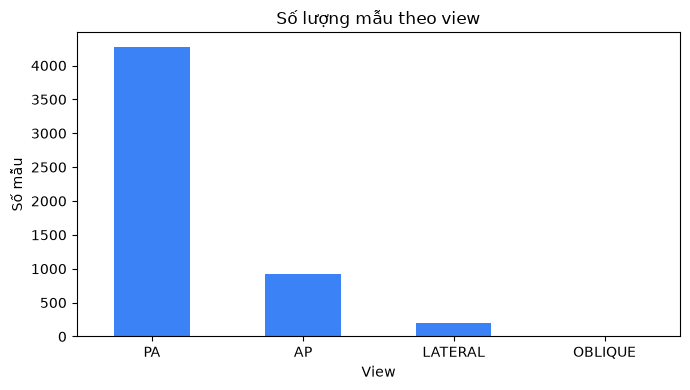

In [4]:
view_counts = df["view"].fillna("<trống>").value_counts()
view_table = pd.DataFrame({"samples": view_counts, "percent": (view_counts / len(df) * 100).round(2)})
display(view_table)
display(pd.crosstab(df["split"], df["view"], margins=True))

ax = view_counts.sort_values(ascending=False).plot(kind="bar", figsize=(7, 4), color="#3b82f6")
ax.set(title="Số lượng mẫu theo view", xlabel="View", ylabel="Số mẫu")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Phân bố giới tính (`sex`)

Bảng và biểu đồ số lượng/tỷ lệ từng giá trị giới tính.

,samples,percent
sex,,
Nam,3169,58.69
Nữ,2231,41.31


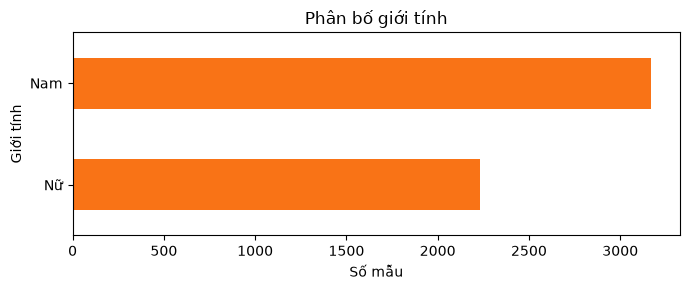

In [5]:
sex_counts = df["sex"].fillna("<trống>").replace("", "<trống>").value_counts()
sex_table = pd.DataFrame({"samples": sex_counts, "percent": (sex_counts / len(df) * 100).round(2)})
display(sex_table)
ax = sex_counts.sort_values().plot(kind="barh", figsize=(7, 3), color="#f97316")
ax.set(title="Phân bố giới tính", xlabel="Số mẫu", ylabel="Giới tính")
plt.tight_layout()
plt.show()

## Phân bố Ghi chú

Bảng giữ toàn bộ giá trị; biểu đồ chỉ hiển thị 15 giá trị phổ biến nhất để dễ đọc.

,samples,percent
Ghi chú,,
Chụp Xquang ngực thẳng,4276,79.19
Chụp ngực tư thế nằm ngửa,922,17.07
Chụp Xquang ngực nghiêng,201,3.72
Chụp Xquang chếch ngực nghiêng,1,0.02


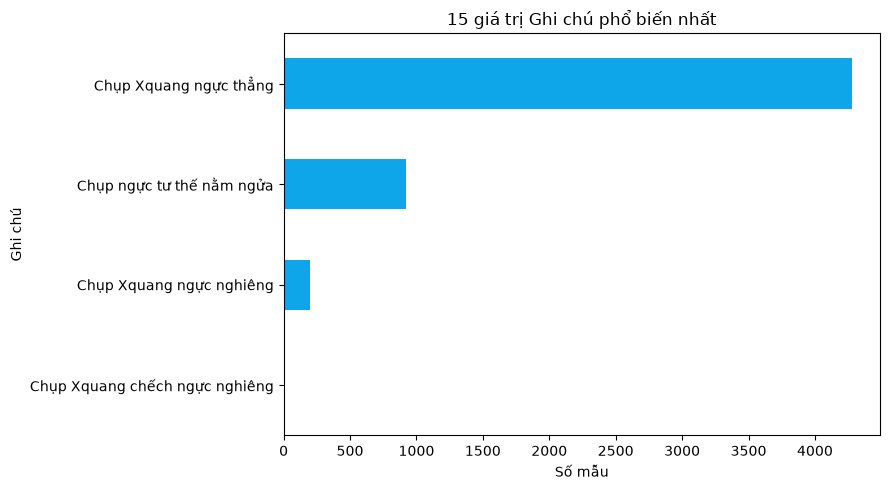

In [6]:
note_counts = df["Ghi chú"].fillna("<trống>").replace("", "<trống>").value_counts()
note_table = pd.DataFrame({"samples": note_counts, "percent": (note_counts / len(df) * 100).round(2)})
display(note_table)
note_counts.head(15).sort_values().plot(kind="barh", figsize=(9, 5), color="#0ea5e9")
plt.title("15 giá trị Ghi chú phổ biến nhất")
plt.xlabel("Số mẫu")
plt.ylabel("Ghi chú")
plt.tight_layout()
plt.show()

## Phân bố Kỹ thuật

Bảng giữ toàn bộ giá trị; biểu đồ chỉ hiển thị 15 giá trị phổ biến nhất để dễ đọc.

,samples,percent
Kỹ thuật,,
Chụp Xquang tim phổi thẳng,4276,79.19
Chụp tim phổi trước sau,922,17.07
Chụp Xquang tim phổi nghiêng,201,3.72
Chụp tim phổi chếch,1,0.02


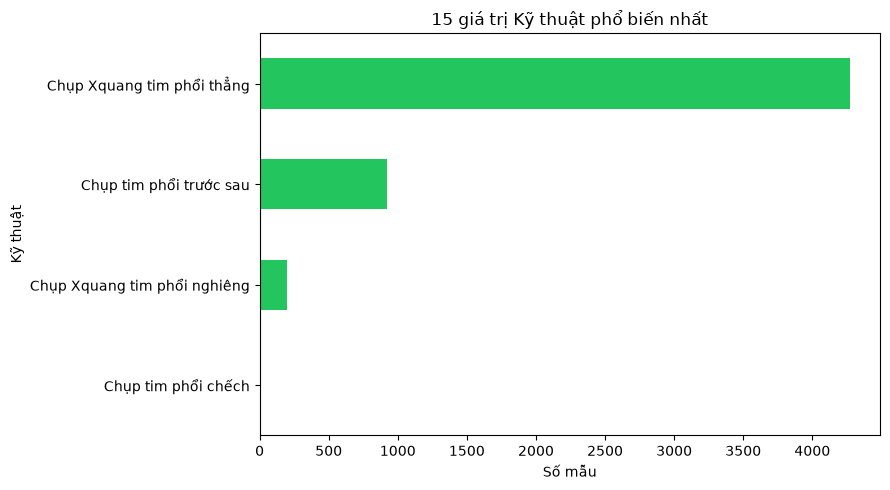

In [7]:
technique_counts = df["Kỹ thuật"].fillna("<trống>").replace("", "<trống>").value_counts()
technique_table = pd.DataFrame({"samples": technique_counts, "percent": (technique_counts / len(df) * 100).round(2)})
display(technique_table)
technique_counts.head(15).sort_values().plot(kind="barh", figsize=(9, 5), color="#22c55e")
plt.title("15 giá trị Kỹ thuật phổ biến nhất")
plt.xlabel("Số mẫu")
plt.ylabel("Kỹ thuật")
plt.tight_layout()
plt.show()

## Tuổi

`Ages` được lưu dưới dạng chuỗi trong Parquet; chuyển sang số để thống kê. Giá trị không chuyển được sẽ thành `NaN`.

,age
count,5400.000000
mean,67.212778
std,13.770218
min,1.000000
25%,61.000000
50%,69.000000
75%,75.000000
max,103.000000


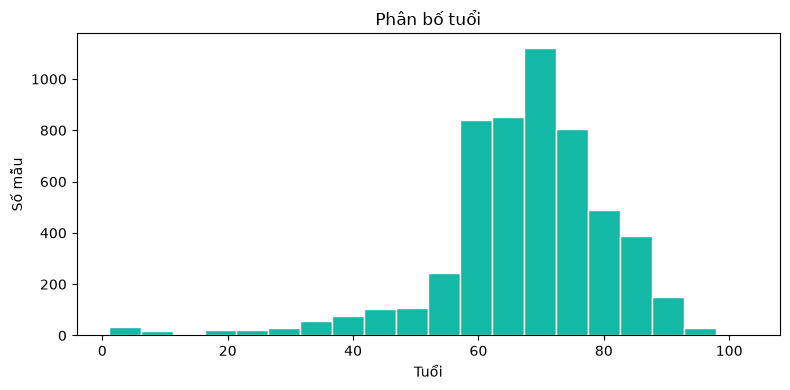

In [8]:
df["age_numeric"] = pd.to_numeric(df["Ages"], errors="coerce")
display(df["age_numeric"].describe().to_frame("age"))

ax = df["age_numeric"].dropna().plot(kind="hist", bins=20, figsize=(8, 4), color="#14b8a6", edgecolor="white")
ax.set(title="Phân bố tuổi", xlabel="Tuổi", ylabel="Số mẫu")
plt.tight_layout()
plt.show()

## Độ dài `findings` và `impressions`

Độ dài tính theo số từ tách bằng khoảng trắng, không phải số token của mô hình.

findings_words                                           \
               count  mean  std   min   25%   50%   75%   max   
split                                                           
test           540.0  47.2  8.2  26.0  41.0  47.0  51.0  84.0   
train         4320.0  47.1  7.7  16.0  41.0  47.0  51.0  96.0   
val            540.0  47.1  8.3  25.0  41.0  47.0  51.0  79.0   

      impressions_words                                          
                  count  mean  std  min   25%   50%   75%   max  
split                                                            
test              540.0  15.2  6.9  4.0  10.0  14.0  18.0  47.0  
train            4320.0  14.9  6.6  4.0  10.0  13.0  18.0  61.0  
val               540.0  15.1  6.8  4.0  10.0  14.0  18.0  45.0

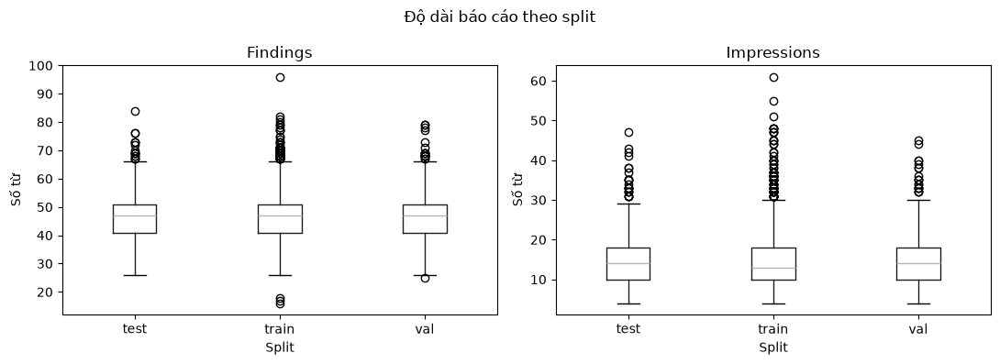

In [9]:
for column in ("findings", "impressions"):
    df[f"{column}_words"] = df[column].fillna("").str.split().str.len()

display(df.groupby("split")[["findings_words", "impressions_words"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, title in zip(axes, ("findings_words", "impressions_words"), ("Findings", "Impressions")):
    df.boxplot(column=column, by="split", ax=ax, grid=False)
    ax.set(title=title, xlabel="Split", ylabel="Số từ")
fig.suptitle("Độ dài báo cáo theo split")
plt.tight_layout()
plt.show()

## Cụm từ thường gặp trong `findings`

Bảng đếm số báo cáo có chứa mỗi cụm từ (không phân biệt hoa/thường). Các nhóm có thể chồng lấp: một báo cáo có thể chứa nhiều cụm từ. Đây không phải thống kê tỷ lệ bệnh.

,term,samples,percent
6,Tim,5384,99.70
0,Phổi,5381,99.65
5,Góc sườn hoành,5299,98.13
4,Cơ hoành,5273,97.65
3,Rốn phổi,4708,87.19
1,Mờ kính,3340,61.85
7,Xương,2998,55.52
2,Tổ chức kẽ,1105,20.46


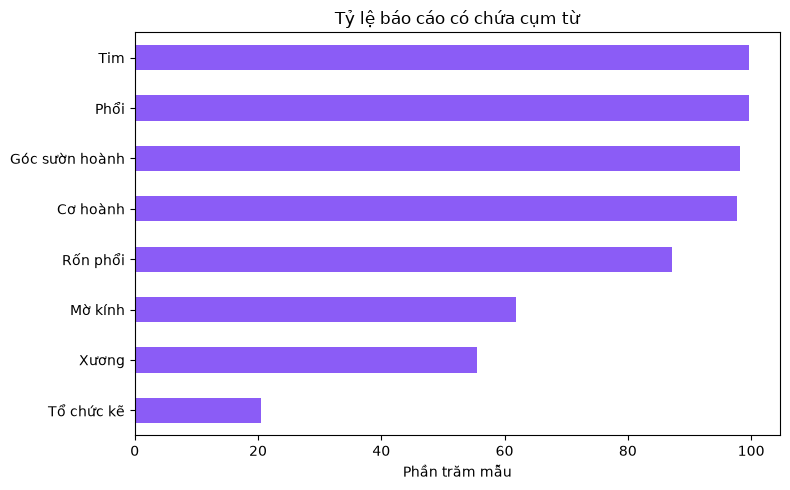

In [10]:
term_patterns = {
    "Phổi": r"phổi",
    "Mờ kính": r"mờ kính",
    "Tổ chức kẽ": r"tổ chức kẽ|dày kẽ",
    "Rốn phổi": r"rốn phổi",
    "Cơ hoành": r"vòm hoành|cơ hoành",
    "Góc sườn hoành": r"góc sườn hoành",
    "Tim": r"tim|bóng tim",
    "Xương": r"xương|xương sườn",
}
findings = df["findings"].fillna("")
term_rows = []
for label, pattern in term_patterns.items():
    count = findings.str.contains(pattern, case=False, regex=True).sum()
    term_rows.append({"term": label, "samples": int(count), "percent": round(count / len(df) * 100, 2)})
term_table = pd.DataFrame(term_rows).sort_values("samples", ascending=False)
display(term_table)

ax = term_table.sort_values("percent").plot.barh(x="term", y="percent", legend=False, figsize=(8, 5), color="#8b5cf6")
ax.set(title="Tỷ lệ báo cáo có chứa cụm từ", xlabel="Phần trăm mẫu", ylabel="")
plt.tight_layout()
plt.show()

## Các dòng mô tả được lặp lại

Chuẩn hóa khoảng trắng và dấu câu ở đầu/cuối để gom các dòng gần giống nhau. Những biến thể nhỏ vẫn có thể được tính thành các dòng riêng.

In [11]:
line_counts = Counter()
for report in findings:
    seen_in_report = set()
    for line in report.splitlines():
        normalized = re.sub(r"^\s*[-•]+\s*", "", line)
        normalized = re.sub(r"\s+", " ", normalized).strip(" .;:").lower()
        if len(normalized) >= 25:
            seen_in_report.add(normalized)
    line_counts.update(seen_in_report)

top_lines = pd.DataFrame(line_counts.most_common(15), columns=["normalized_line", "reports"])
display(top_lines)

,normalized_line,reports
0,bờ vòm hoành hai bên đều hai góc sườn hoành nhọn,2580
1,phổi hai bên kém sáng mờ kính rải rác rốn phổi...,2028
2,lồng ngực cân đối không thấy bất thường xương,1636
3,bóng mờ tim không to các cung tim trong giới h...,1420
4,"bờ vòm hoành hai bên đều, hai góc sườn hoành nhọn",1398
5,"lồng ngực cân đối, không thấy bất thường xương",1140
6,"bóng mờ tim không to, các cung tim trong giới ...",908
7,"phổi hai bên kém sáng, mờ kính rải rác, rốn ph...",791
8,góc sườn hoành hai bên nhọn,780
9,rốn phổi hai bên không thấy bất thường,638


## Xem ảnh và báo cáo mẫu

Notebook dùng ba ảnh mẫu đã xuất trong `data/sample/`; ảnh và phần mô tả được hiển thị cùng nhau.

### Mẫu 1 · PA

Tuổi: 62 · Giới tính: Nữ

**Findings**

- Phổi hai bên kém sáng, mờ kính rải rác, rốn phổi tăng đậm nhẹ.
- Bờ vòm hoành hai bên đều, hai góc sườn hoành nhọn.
- Bóng mờ tim không to, các cung tim trong giới hạn sinh lý.

**Impressions**

- Hình ảnh nghĩ nhiều đến tổn thương phổi kẽ.

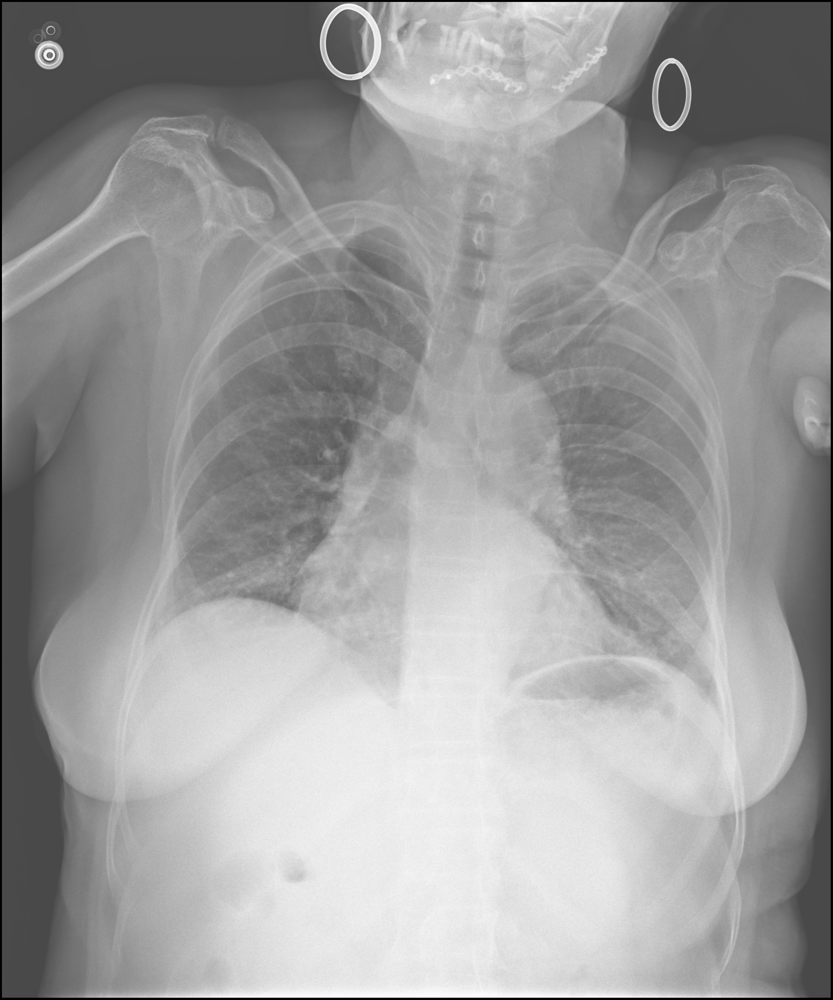

### Mẫu 2 · PA

Tuổi: 69 · Giới tính: Nữ

**Findings**

- Phổi hai bên kém sáng, đám mờ không đều thùy trên phổi trái, vài nốt vôi hóa nhỏ kèm xơ hóa vùng đỉnh phổi hai bên, rốn phổi tăng đậm nhẹ.
- Bờ vòm hoành hai bên đều, hai góc sườn hoành nhọn.
- Bóng mờ tim không to, các cung tim trong giới hạn sinh lý.

**Impressions**

- Hình ảnh đám mờ không đều thùy trên phổi trái.
- vài nốt vôi hóa nhỏ kèm xơ hóa vùng đỉnh phổi hai bên.

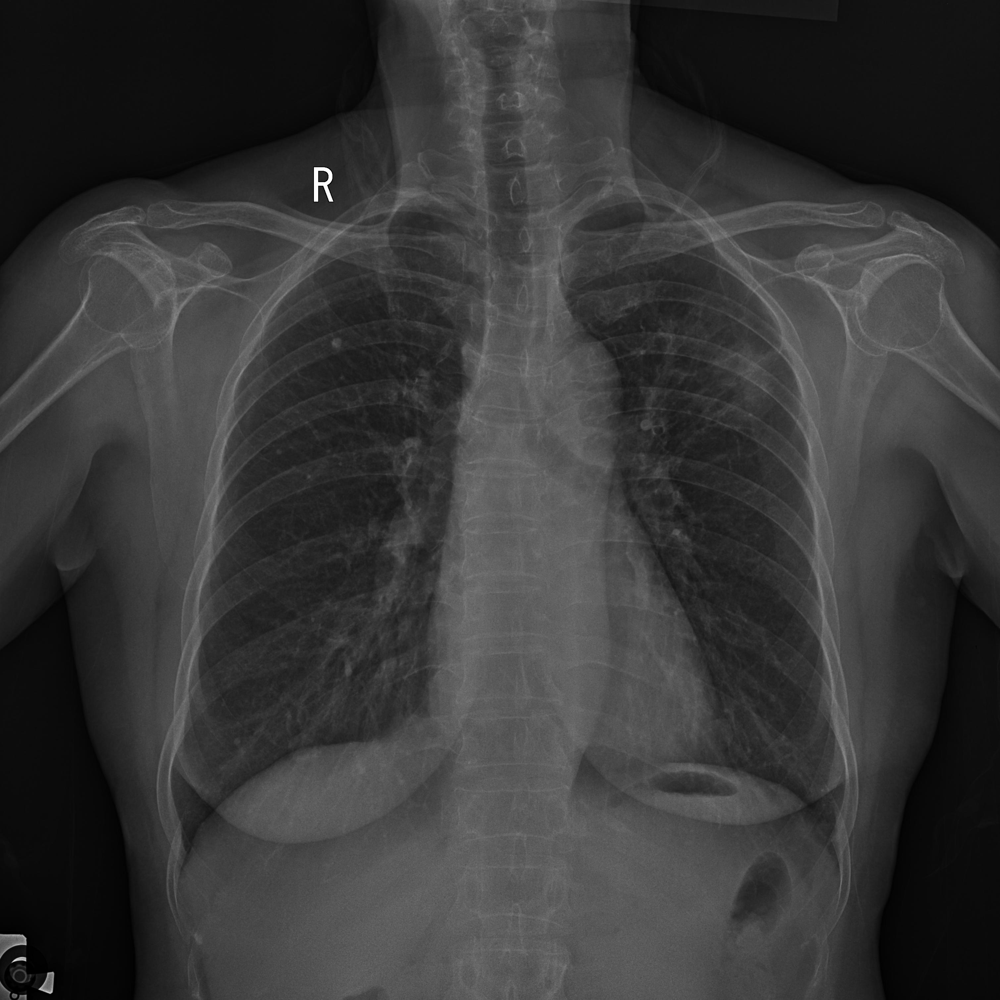

### Mẫu 3 · PA

Tuổi: 61 · Giới tính: Nam

**Findings**

- Lồng ngực cân đối không thấy bất thường xương
- Dày tổ chức kẽ kèm mờ kính rải rác hai phổi
- Bờ vòm hoành hai bên đều. Góc sườn hoành hai bên nhọn
- Bóng tim không to. Các bờ trung thất trong giới hạn bình thường.

**Impressions**

- Hình ảnh tổn thương phổi kẽ.

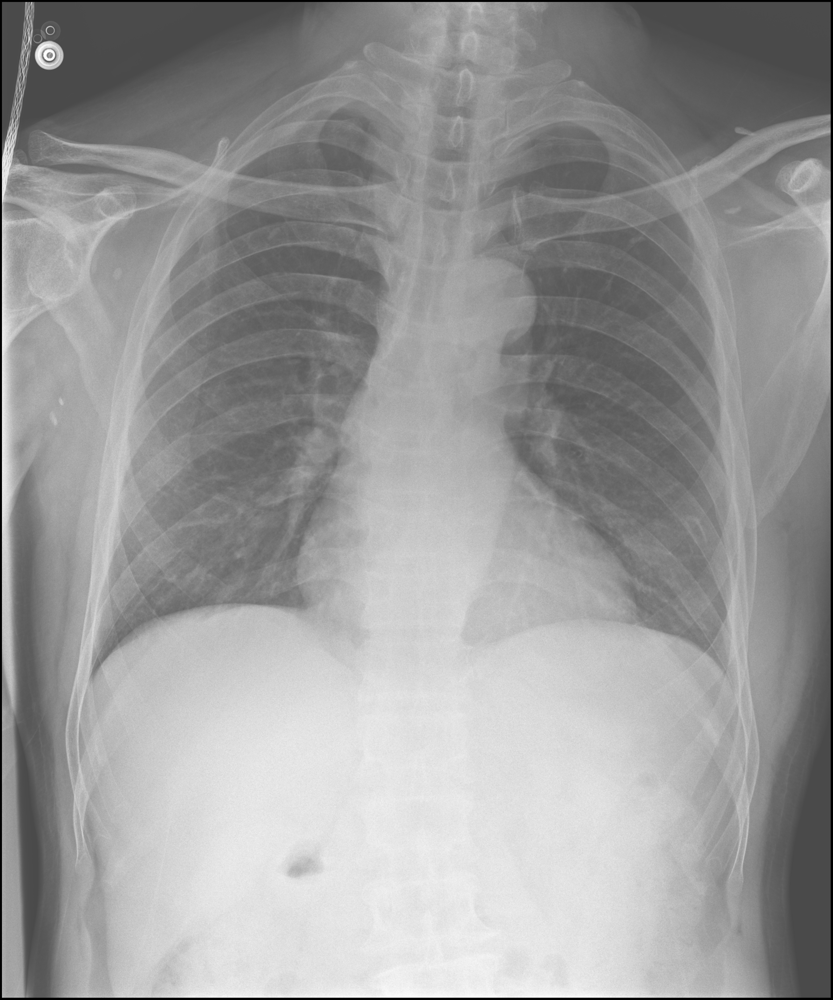

In [12]:
sample_json = SAMPLE_DIR / "samples.json"
if sample_json.exists():
    samples = json.loads(sample_json.read_text(encoding="utf-8"))
    for sample in samples:
        display(Markdown(
            f"### Mẫu {sample['sample']} · {sample.get('view', 'N/A')}\n\n"
            f"Tuổi: {sample.get('Ages', 'N/A')} · Giới tính: {sample.get('sex', 'N/A')}\n\n"
            f"**Findings**\n\n{sample.get('findings', '')}\n\n"
            f"**Impressions**\n\n{sample.get('impressions', '')}"
        ))
        image_path = SAMPLE_DIR / sample['image']
        if image_path.exists():
            display(Image(filename=str(image_path), width=600))
else:
    print(f"Không tìm thấy sample JSON: {sample_json}")

## Ghi chú khi diễn giải

- `findings` là mô tả hình ảnh; `impressions` là phần kết luận của báo cáo.
- Từ khóa có thể xuất hiện trong câu phủ định hoặc câu mô tả bình thường, nên không dùng tỷ lệ này như tỷ lệ mắc bệnh.
- Các thống kê văn bản không thay thế việc đọc ảnh hoặc đánh giá chuyên môn.